<a href="https://colab.research.google.com/github/kulanigayathree/J26-IT-364/blob/model%2FOil-Spill-Detection/notebooks/oil-spill/C4_01_download_data.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# C4 – Step 2: Download the DARTIS 2019 dataset into Colab
**Dataset:** Yang & Singha (2025), *Oil slicks, look-alikes and other remarkable SAR signatures in Sentinel-1 imagery in the Eastern Mediterranean Sea in 2019*. PANGAEA, https://doi.org/10.1594/PANGAEA.980773 (CC-BY-4.0)

Run the cells **from top to bottom, one by one** (▶️ or Shift+Enter).

## 1. Connect Google Drive
When the popup appears: **Connect → choose account → Allow**.

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


## 2. Create folders
A data folder inside the `C4_OilSpill` folder on Drive.

In [ ]:
import os
DRIVE_DIR = '/content/drive/MyDrive/C4_OilSpill'
DATA_DIR  = f'{DRIVE_DIR}/data'
LOCAL_DIR = '/content/DARTIS'          # fast local disk in Colab
IMG_DIR   = f'{LOCAL_DIR}/files'
for d in [DATA_DIR, IMG_DIR]:
    os.makedirs(d, exist_ok=True)
print('Folders ready ✅')

Folders ready ✅


## 3. Get the table (.tab) file
Downloads the PANGAEA metadata table directly into Colab.

In [ ]:
TAB_PATH = f'{DATA_DIR}/DARTIS_2019.tab'
if not os.path.exists(TAB_PATH):
    !wget -q -O "{TAB_PATH}" "https://doi.pangaea.de/10.1594/PANGAEA.980773?format=textfile"
print('Size (KB):', os.path.getsize(TAB_PATH)//1024)

Size (KB): 2354


## 4. Read the table
Column names are long, so only the short name inside the last brackets is kept (e.g. `start_time`, `obj_patchloc_xmin`).

**Image set codes:** `ow` = oil / open water, `oc` = oil / coastal, `nw` = no oil / open water, `nc` = no oil / coastal

In [ ]:
import pandas as pd, re

with open(TAB_PATH, encoding='utf-8') as f:
    lines = f.readlines()
start = [i for i, l in enumerate(lines) if l.strip() == '*/'][0] + 1
df = pd.read_csv(TAB_PATH, sep='\t', skiprows=start)

def short(c):
    m = re.findall(r'\(([^()]*)\)', c)
    return m[-1] if m else c
df.columns = ['subset'] + [short(c) for c in df.columns[1:]]
df['is_oil'] = df['subset'].isin(['ow', 'oc'])
df['start_time'] = pd.to_datetime(df['start_time'])

print('Rows (oil objects + no-oil images):', len(df))
print('Unique images:', df['jpg_file'].nunique())
print(df.groupby('subset')['jpg_file'].nunique().rename('images'))
df.head()

Rows (oil objects + no-oil images): 5515
Unique images: 3655
subset
nc     351
nw    1939
oc     375
ow     990
Name: images, dtype: int64


,subset,jpg_file,xml_file,tag,patch_name,start_time,end_time,Sentinel_ID,patch_width,patch_height,...,obj_br_lon,obj_br_lat,obj_bl_lon,obj_bl_lat,obj_patchloc_xmin,obj_patchloc_ymin,obj_patchloc_xmax,obj_patchloc_ymax,label_size,is_oil
0,ow,ow-0001.jpg,ow-0001.xml,ow-0001-01-000001,S1_20190101_034235_034350_VV_1,2019-01-01 03:42:35,2019-01-01T03:43:50,S1B_IW_GRDH_1SDV_20190101T034300_20190101T0343...,640,640,...,33.054535,33.255456,33.059407,33.254776,345.0,297.0,368.0,343.0,1058.0,True
1,ow,ow-0002.jpg,ow-0002.xml,ow-0002-01-000002,S1_20190104_155638_155818_VV_2,2019-01-04 15:56:38,2019-01-04T15:58:18,S1A_IW_GRDH_1SDV_20190104T155703_20190104T1557...,640,640,...,32.031087,31.691326,32.024630,31.690382,309.0,282.0,340.0,342.0,1860.0,True
2,ow,ow-0003.jpg,ow-0003.xml,ow-0003-01-000003,S1_20190110_155611_155635_VV_9,2019-01-10 15:56:11,2019-01-10T15:56:35,S1B_IW_GRDH_1SDV_20190110T155611_20190110T1556...,640,640,...,30.631705,31.575859,30.621997,31.574357,297.0,309.0,344.0,331.0,1034.0,True
3,ow,ow-0004.jpg,ow-0004.xml,ow-0004-01-000004,S1_20190110_155611_155635_VV_10,2019-01-10 15:56:11,2019-01-10T15:56:35,S1B_IW_GRDH_1SDV_20190110T155611_20190110T1556...,640,640,...,31.191345,31.712193,31.188644,31.711781,347.0,292.0,360.0,311.0,247.0,True
4,ow,ow-0004.jpg,ow-0004.xml,ow-0004-02-000005,S1_20190110_155611_155635_VV_10,2019-01-10 15:56:11,2019-01-10T15:56:35,S1B_IW_GRDH_1SDV_20190110T155611_20190110T1556...,640,640,...,31.237558,31.773555,31.232986,31.772857,614.0,503.0,636.0,604.0,2222.0,True


### Understanding the dataset (important!)
- **Oil images (ow, oc):** one image can contain several oil slicks, so every slick has **its own row** with its box position (`obj_patchloc_xmin/ymin/xmax/ymax`).
- **No-oil images (nw, nc):** look-alikes and other features. These have **no boxes**; the whole image is labelled "no oil".
- Every row has a **date/time** (`start_time`) and **lat/lon**, so wind data (ERA5) can be added later.

In [ ]:
print('Oil objects  :', df['is_oil'].sum())
print('Oil images   :', df.loc[df.is_oil, 'jpg_file'].nunique())
print('No-oil images:', df.loc[~df.is_oil, 'jpg_file'].nunique())
sizes = df.drop_duplicates('jpg_file')['patch_width']
print('Image size   : most are', sizes.mode()[0], 'x', sizes.mode()[0], f'(min {sizes.min()}, max {sizes.max()})')

Oil objects  : 3225
Oil images   : 1365
No-oil images: 2290
Image size   : most are 640 x 640 (min 640, max 4964)


## 5. Download images + XML files
5,020 files (3,655 images + 1,365 XML). 16 files are downloaded in parallel, so this takes about **5–15 minutes**. Wait until the cell finishes.
If it stops, run it again: files already downloaded are skipped.

In [ ]:
import requests
from concurrent.futures import ThreadPoolExecutor
from tqdm.auto import tqdm

BASE = 'https://download.pangaea.de/dataset/980773/files/'
names = pd.concat([df['jpg_file'], df['xml_file']]).dropna().unique().tolist()
print('Files to download:', len(names))

def fetch(name):
    out = os.path.join(IMG_DIR, name)
    if os.path.exists(out) and os.path.getsize(out) > 0:
        return 'skip'
    for _ in range(3):
        try:
            r = requests.get(BASE + name, timeout=60)
            if r.status_code == 200:
                with open(out, 'wb') as f:
                    f.write(r.content)
                return 'ok'
        except Exception:
            pass
    return 'fail'

with ThreadPoolExecutor(max_workers=16) as ex:
    results = list(tqdm(ex.map(fetch, names), total=len(names)))

print({k: results.count(k) for k in set(results)})

Files to download: 5020


  0%|          | 0/5020 [00:00<?, ?it/s]

{'ok': 5020}


## 6. Save a backup to Drive
Files in `/content` are deleted when the Colab session ends, so they are **packed into one file (tar)** and saved to Drive. No need to download again later.

In [ ]:
TAR_PATH = f'{DATA_DIR}/DARTIS_2019_files.tar'
!tar -cf "{TAR_PATH}" -C "{LOCAL_DIR}" files
print('Backup size (MB):', os.path.getsize(TAR_PATH)//(1024*1024))

Backup size (MB): 482


## ⭐ (Later sessions) Restore files from Drive
In a new session, **run Cells 1–4, then run only this cell**. Cells 5–6 do not need to be run again.

In [ ]:
TAR_PATH = f'{DATA_DIR}/DARTIS_2019_files.tar'
if not os.listdir(IMG_DIR):
    !tar -xf "{TAR_PATH}" -C "{LOCAL_DIR}"
print('Files in local folder:', len(os.listdir(IMG_DIR)))

Files in local folder: 5020


## 7. View sample images 👀
Top row: **oil** (red boxes = oil slicks). Bottom row: **no oil** (look-alikes / other).

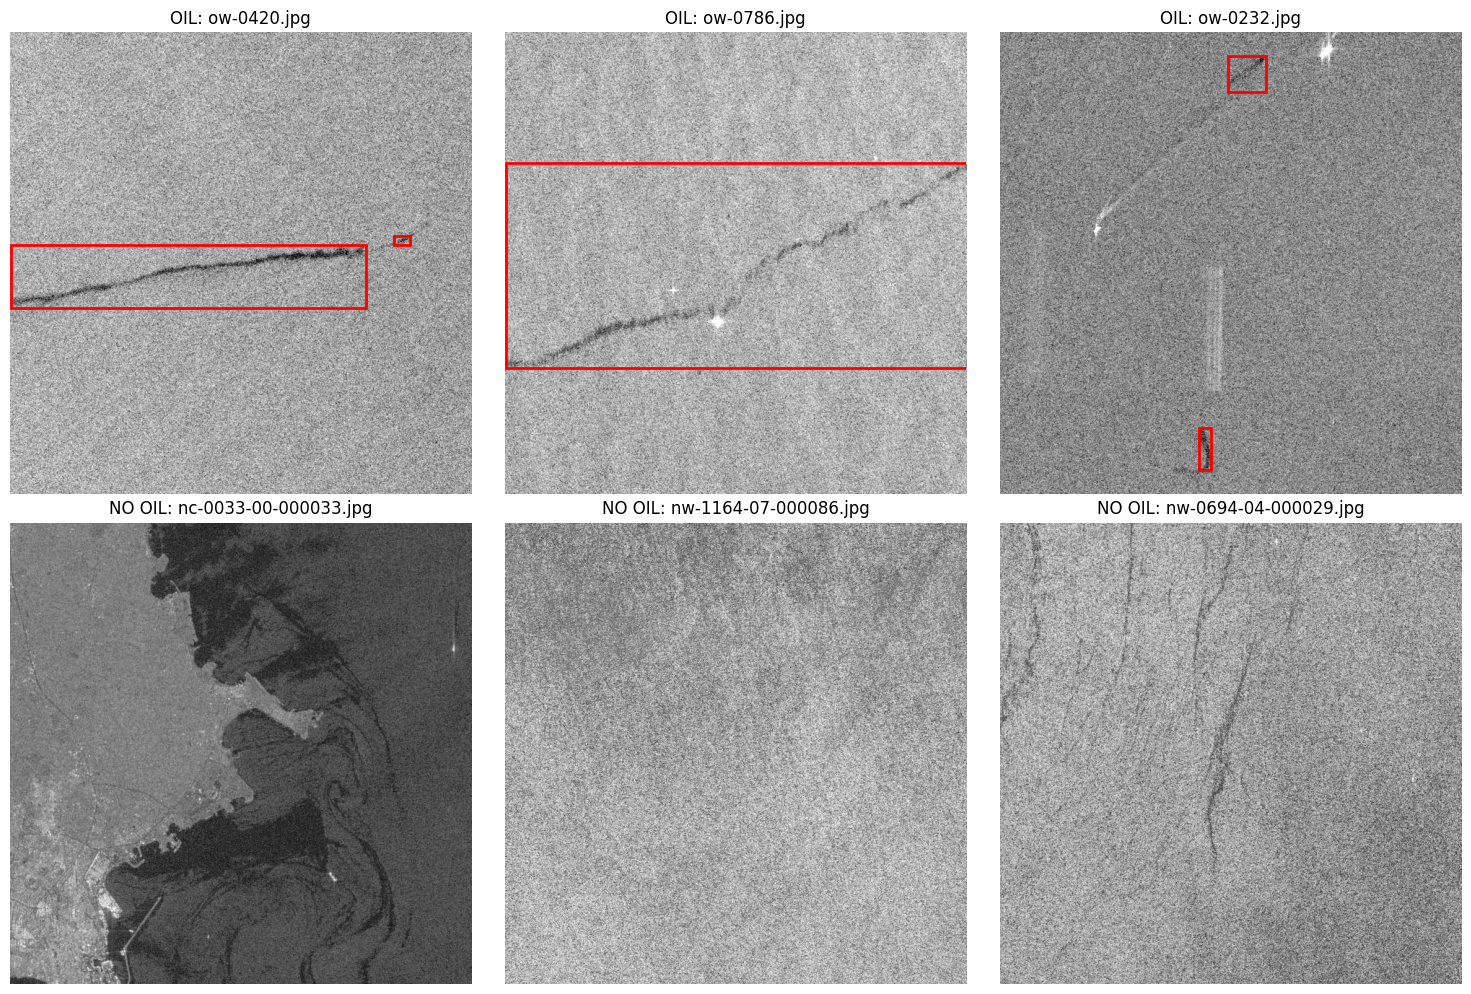

In [ ]:
import matplotlib.pyplot as plt, matplotlib.patches as patches
from PIL import Image

oil_imgs   = df[df.is_oil]['jpg_file'].drop_duplicates().sample(3, random_state=1)
nooil_imgs = df[~df.is_oil]['jpg_file'].drop_duplicates().sample(3, random_state=1)

fig, axes = plt.subplots(2, 3, figsize=(15, 10))
for ax, name in zip(axes[0], oil_imgs):
    ax.imshow(Image.open(f'{IMG_DIR}/{name}'), cmap='gray')
    for _, r in df[df.jpg_file == name].iterrows():
        x0, y0 = r.obj_patchloc_xmin, r.obj_patchloc_ymin
        ax.add_patch(patches.Rectangle((x0, y0), r.obj_patchloc_xmax - x0, r.obj_patchloc_ymax - y0,
                                       fill=False, edgecolor='red', linewidth=2))
    ax.set_title(f'OIL: {name}'); ax.axis('off')
for ax, name in zip(axes[1], nooil_imgs):
    ax.imshow(Image.open(f'{IMG_DIR}/{name}'), cmap='gray')
    ax.set_title(f'NO OIL: {name}'); ax.axis('off')
plt.tight_layout()
os.makedirs(f'{DRIVE_DIR}/results', exist_ok=True)
plt.savefig(f'{DRIVE_DIR}/results/01_sample_images.png', dpi=120)
plt.show()

## 8. Save the clean table
Later notebooks use this CSV file.

In [ ]:
df.to_csv(f'{DATA_DIR}/DARTIS_2019_metadata.csv', index=False)
print('Saved ✅', f'{DATA_DIR}/DARTIS_2019_metadata.csv')

Saved ✅ /content/drive/MyDrive/C4_OilSpill/data/DARTIS_2019_metadata.csv


## ✅ Done!
**🔔 COMMIT:** File → Save a copy in GitHub → `notebooks/oil-spill/C4_01_download_data.ipynb` → `feat(oil-spill): download and explore DARTIS 2019 Sentinel-1 dataset`